# SOCIAL MEDIA ENGAGEMENT ANALYTICS USING PYTHON

### Module End Assignment – Python for Data Analysis
#### Project Overview

Social media platforms generate large amounts of data through likes, comments, shares, impressions, watch time, and other engagement activities. This project focuses on analyzing social media engagement data using Python. The dataset contains information about users, post types, content categories, engagement metrics, demographics, devices, and sentiment.

##### Importing Libraries

The required Python libraries are imported to perform data manipulation, numerical calculations, statistical analysis, and visualization.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [7]:
##### Regular expression library for text processing
import re

##### Ignore warnings
import warnings
warnings.filterwarnings("ignore")

##### Jupyter magic command for displaying plots
%matplotlib inline

print("All libraries imported successfully.")

All libraries imported successfully.


In [8]:
# Load and show Dataset

df = pd.read_csv(r"C:\Entri_APARNA\Python\social_media_engagement_5000.csv")
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [10]:
# Display first five rows
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [12]:
# Display last five row
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [15]:
# Dataset dimensions
df.shape

(5000, 19)

In [17]:
# Column names
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [18]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [19]:
# Data types
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [20]:
# Statistical summary
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,393698.224800,0.964356
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348


In [21]:
df.nunique()

user_id             4862
age                   52
gender                 3
country               10
post_id             4991
post_type              4
post_category          8
likes               4292
comments            2400
shares              1827
watch_time_sec      3690
impression_count    4870
posted_at            729
follower_count      4983
is_verified            2
device_type            3
sentiment              3
hashtags             761
engagement_rate     5000
dtype: int64

In [22]:
# Missing values
print("Missing values:")
display(df.isnull().sum())

Missing values:


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

#### Basic NumPy operations
##### Create a NumPy array

In [24]:
likes_array = np.array([100, 200, 300, 400, 500])
likes_array

array([100, 200, 300, 400, 500])

In [26]:
# array dimensions and shape
likes_array.ndim

1

In [27]:
likes_array.shape

(5,)

In [28]:
likes_array.size

5

In [29]:
# basic mathematical operations
likes_array + 10

array([110, 210, 310, 410, 510])

In [30]:
likes_array * 2

array([ 200,  400,  600,  800, 1000])

In [31]:
likes_array / 2

array([ 50., 100., 150., 200., 250.])

In [33]:
# Calculate basic statistical values
print(np.mean(likes_array))
print(np.median(likes_array))
print(np.max(likes_array))
print(np.min(likes_array))

300.0
300.0
500
100


In [34]:
# Create a copy of the dataset 
df_clean = df.copy()
df_clean.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


#### Check and handle missing values

In [35]:
#Check missing values
df_clean.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [36]:
# Calculate the percentage of missing values
(df_clean.isnull().sum() / len(df_clean)) * 100

user_id             0.0
age                 3.0
gender              3.0
country             0.0
post_id             0.0
post_type           0.0
post_category       0.0
likes               3.0
comments            3.0
shares              3.0
watch_time_sec      0.0
impression_count    0.0
posted_at           0.0
follower_count      0.0
is_verified         0.0
device_type         0.0
sentiment           3.0
hashtags            0.0
engagement_rate     0.0
dtype: float64

In [37]:
# Handle missing numerical values using median
numeric_columns = df_clean.select_dtypes(include=np.number).columns

df_clean[numeric_columns] = df_clean[numeric_columns].fillna(
    df_clean[numeric_columns].median()
)

In [38]:
# Handle missing categorical values using mode
categorical_columns = df_clean.select_dtypes(include="object").columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

In [39]:
# Check missing values after treatment
df_clean.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

#### Remove duplicate records

In [40]:
# Check duplicate records
df_clean.duplicated().sum()

np.int64(0)

In [41]:
# Remove duplicate records
df_clean = df_clean.drop_duplicates()

In [42]:
# Check the dataset after removing duplicates
df_clean.shape

(5000, 19)

#### Data formatting and type conversion

In [43]:
# Remove unwanted spaces and standardize text columns
text_columns = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment',
    'hashtags'
]

for column in text_columns:
    df_clean[column] = df_clean[column].astype(str).str.strip()

In [44]:
# Standardize categorical values
category_columns = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for column in category_columns:
    df_clean[column] = df_clean[column].str.lower()

In [45]:
print("\n--- Unique Values Per Column ---")
for column in category_columns:
    print(f"{column}: {df_clean[column].unique()}")


--- Unique Values Per Column ---
gender: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str
country: <ArrowStringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: str
post_type: <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
post_category: <ArrowStringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str
device_type: <ArrowStringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str
sentiment: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


In [46]:
# Convert posted_at into datetime format
df_clean['posted_at'] = pd.to_datetime(
    df_clean['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [47]:
# Check data types after conversion
df_clean.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [48]:
# Check and handle unrealistic values
# Check numerical columns for negative values
numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate'
]

(df_clean[numeric_columns] < 0).sum()

age                 0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
follower_count      0
engagement_rate     0
dtype: int64

In [49]:
# Replace negative values with missing values.
for column in numeric_columns:
    df_clean.loc[df_clean[column] < 0, column] = np.nan

In [50]:
# Fill the resulting missing values using the median.
for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

In [51]:
# Check the updated dataset.
df_clean[numeric_columns].describe()

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000,5000.000000
mean,38.440400,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,393698.224800,0.964356
std,14.687151,5702.293017,856.393312,570.8552,2308.096459,28844.939104,230927.884535,5.318029
min,13.000000,10.000000,0.000000,0.0000,0.000000,105.000000,87.000000,0.006363
25%,26.000000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,194480.000000,0.145781
50%,38.000000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,388982.000000,0.253896
75%,51.000000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,589744.250000,0.504794
max,64.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,799533.000000,191.504348


#### Outlier detection and treatment
We will use the IQR (Interquartile Range) method to identify and treat outliers.

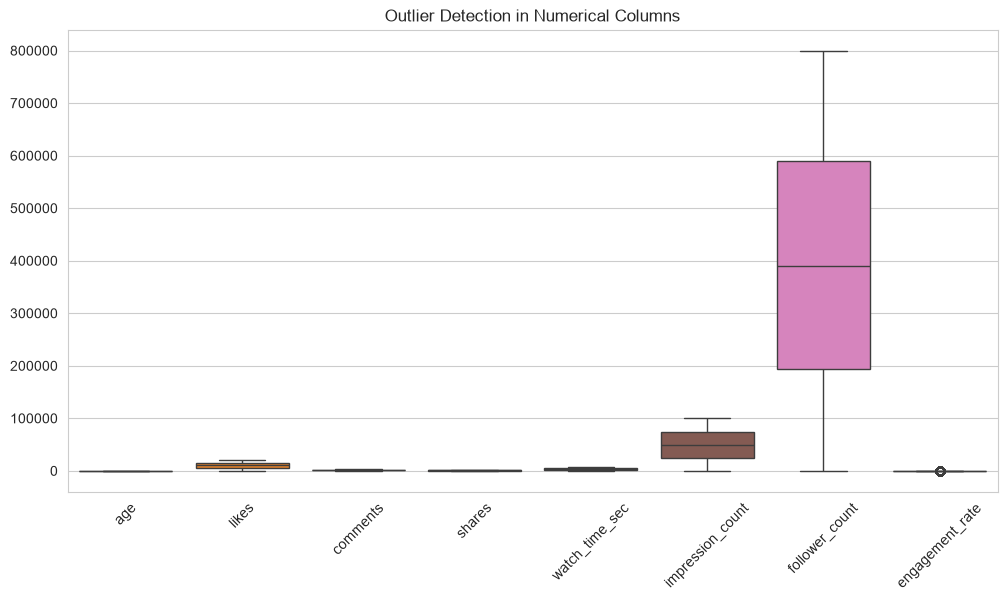

In [53]:
# Identify outliers using boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[numeric_columns])
plt.xticks(rotation=45)
plt.title("Outlier Detection in Numerical Columns")
plt.show()

In [54]:
# Calculate IQR and identify outliers
for column in numeric_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_limit) |
        (df_clean[column] > upper_limit)
    ]

    outliers.shape

In [55]:
# Treat outliers using the IQR capping method
for column in numeric_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_clean[column] = df_clean[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

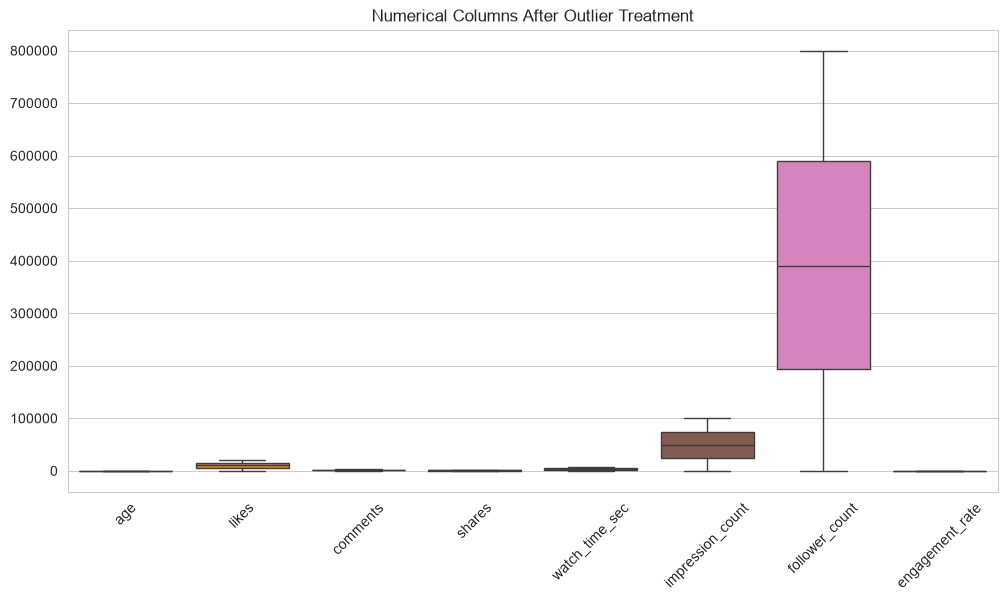

In [56]:
# Check the dataset after outlier treatment
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_clean[numeric_columns])

plt.xticks(rotation=45)
plt.title("Numerical Columns After Outlier Treatment")
plt.show()

#### Feature creation and text processing

In [59]:
# Calculate the number of hashtags in each post
df_clean['hashtag_count'] = df_clean['hashtags'].str.count('#')
df_clean[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [60]:
# Create an engagement score
# Engagement score is calculated using likes, comments and shares.
df_clean['engagement_score'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

df_clean[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [61]:
# Extract the posting date
df_clean['post_date'] = df_clean['posted_at'].dt.date
df_clean[['posted_at', 'post_date']].head()

,posted_at,post_date
0,2022-12-17,2022-12-17
1,2023-06-02,2023-06-02
2,2023-05-07,2023-05-07
3,2023-02-12,2023-02-12
4,2023-05-23,2023-05-23


In [62]:
# Extract the posting hour
df_clean['post_hour'] = df_clean['posted_at'].dt.hour
df_clean[['posted_at', 'post_hour']].head()

,posted_at,post_hour
0,2022-12-17,0
1,2023-06-02,0
2,2023-05-07,0
3,2023-02-12,0
4,2023-05-23,0


In [63]:
# Explore categorical variables
# Check unique values
df_clean['gender'].unique()

<ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str

In [64]:
df_clean['post_type'].unique()

<ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

In [65]:
df_clean['post_category'].unique()

<ArrowStringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str

In [66]:
# Count the values in categorical columns
df_clean['gender'].value_counts()

gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

In [67]:
df_clean['post_type'].value_counts()

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [68]:
df_clean['post_category'].value_counts()

post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

In [69]:
df_clean['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

### Save the cleaned dataset

In [121]:
df_clean.to_csv(
    'cleaned_social_media_engagement.csv',
    index=False
)
print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [122]:
from IPython.display import FileLink

FileLink('cleaned_social_media_engagement.csv')

C:\Users\Samsung\anaconda_projects\0291c257-0250-4372-ba07-5af40ae81378\cleaned_social_media_engagement.csv

#### Grouping and data analysis

In [70]:
# Average likes by post type
df_clean.groupby('post_type')['likes'].mean().sort_values(
    ascending=False
)

post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64

In [71]:
# Average engagement score by post category
df_clean.groupby('post_category')['engagement_score'].mean().sort_values(
    ascending=False
)

post_category
music        12788.549606
food         12739.200675
tech         12686.490226
travel       12650.559167
lifestyle    12639.539539
education    12578.270206
fitness      12457.791852
fashion      12356.420875
Name: engagement_score, dtype: float64

In [72]:
# Average impressions by country
df_clean.groupby('country')['impression_count'].mean().sort_values(
    ascending=False
)

country
india        52462.386916
france       51727.673387
usa          51263.872255
uk           51119.393509
japan        49616.135593
brazil       49193.174603
uae          48928.413519
canada       48703.150097
germany      48605.406122
australia    48346.383367
Name: impression_count, dtype: float64

In [73]:
# Average engagement rate by sentiment
df_clean.groupby('sentiment')['engagement_rate'].mean().sort_values(
    ascending=False
)

sentiment
negative    0.380845
neutral     0.379722
positive    0.372769
Name: engagement_rate, dtype: float64

#### Data wrangling using concat and groupby

In [75]:
# Create category-wise summary
category_summary = df_clean.groupby('post_category').agg(
    total_posts=('post_id', 'count'),
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_score', 'mean')
).reset_index()

category_summary

,post_category,total_posts,average_likes,average_comments,average_shares,average_engagement
0,education,631,10126.487322,1455.337559,996.445325,12578.270206
1,fashion,594,9843.356902,1530.540404,982.523569,12356.420875
2,fitness,675,9914.602222,1501.142222,1042.047407,12457.791852
3,food,593,10225.522766,1510.876897,1002.801012,12739.200675
4,lifestyle,607,10180.559308,1467.840198,991.140033,12639.539539
5,music,635,10205.749606,1558.710236,1024.089764,12788.549606
6,tech,665,10171.571429,1505.548872,1009.369925,12686.490226
7,travel,600,10196.304167,1485.948333,968.306667,12650.559167


In [76]:
# Create country-wise summary
country_summary = df_clean.groupby('country').agg(
    total_posts=('post_id', 'count'),
    average_impressions=('impression_count', 'mean'),
    average_engagement_rate=('engagement_rate', 'mean')
).reset_index()

country_summary

,country,total_posts,average_impressions,average_engagement_rate
0,australia,493,48346.383367,0.401197
1,brazil,504,49193.174603,0.381073
2,canada,513,48703.150097,0.382452
3,france,496,51727.673387,0.373147
4,germany,490,48605.406122,0.384047
5,india,535,52462.386916,0.343157
6,japan,472,49616.135593,0.390418
7,uae,503,48928.413519,0.388628
8,uk,493,51119.393509,0.359632
9,usa,501,51263.872255,0.363791


In [77]:
# Combine the summaries using concat
combined_summary = pd.concat(
    [category_summary, country_summary],
    ignore_index=True
)

combined_summary

,post_category,total_posts,average_likes,average_comments,average_shares,average_engagement,country,average_impressions,average_engagement_rate
0,education,631,10126.487322,1455.337559,996.445325,12578.270206,NaN,NaN,NaN
1,fashion,594,9843.356902,1530.540404,982.523569,12356.420875,NaN,NaN,NaN
2,fitness,675,9914.602222,1501.142222,1042.047407,12457.791852,NaN,NaN,NaN
3,food,593,10225.522766,1510.876897,1002.801012,12739.200675,NaN,NaN,NaN
4,lifestyle,607,10180.559308,1467.840198,991.140033,12639.539539,NaN,NaN,NaN
5,music,635,10205.749606,1558.710236,1024.089764,12788.549606,NaN,NaN,NaN
6,tech,665,10171.571429,1505.548872,1009.369925,12686.490226,NaN,NaN,NaN
7,travel,600,10196.304167,1485.948333,968.306667,12650.559167,NaN,NaN,NaN
8,NaN,493,NaN,NaN,NaN,NaN,australia,48346.383367,0.401197
9,NaN,504,NaN,NaN,NaN,NaN,brazil,49193.174603,0.381073


#### Statistical analysis

In [78]:
# Calculate mean, median, mode, standard deviation, variance and percentiles
statistics_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

statistics_summary = {}

for column in statistics_columns:

    statistics_summary[column] = {
        'Mean': df_clean[column].mean(),
        'Median': df_clean[column].median(),
        'Mode': df_clean[column].mode()[0],
        'Standard Deviation': df_clean[column].std(),
        'Variance': df_clean[column].var(),
        '25th Percentile': df_clean[column].quantile(0.25),
        '50th Percentile': df_clean[column].quantile(0.50),
        '75th Percentile': df_clean[column].quantile(0.75)
    }

statistics_df = pd.DataFrame(statistics_summary).T

statistics_df

,Mean,Median,Mode,Standard Deviation,Variance,25th Percentile,50th Percentile,75th Percentile
likes,10106.997400,10105.500000,10105.500000,5702.293017,3.251615e+07,5235.000000,10105.500000,14959.000000
comments,1502.039800,1497.000000,1497.000000,856.393312,7.334095e+05,792.000000,1497.000000,2235.250000
shares,1002.910600,1012.000000,1012.000000,570.855200,3.258757e+05,511.000000,1012.000000,1483.000000
watch_time_sec,4014.503200,4034.500000,916.000000,2308.096459,5.327309e+06,2017.750000,4034.500000,6020.250000
engagement_rate,0.376443,0.253896,1.043313,0.315379,9.946394e-02,0.145781,0.253896,0.504794
follower_count,393698.224800,388982.000000,497502.000000,230927.884535,5.332769e+10,194480.000000,388982.000000,589744.250000


#### Functions, loops and sorting

In [79]:
# Create a function to classify engagement levels
def engagement_level(score):

    if score < 5000:
        return 'Low'

    elif score < 15000:
        return 'Medium'

    else:
        return 'High'

In [80]:
# Apply the function to the dataset
df_clean['engagement_level'] = df_clean['engagement_score'].apply(
    engagement_level
)

df_clean[['engagement_score', 'engagement_level']].head()

,engagement_score,engagement_level
0,8522.0,Medium
1,16163.0,High
2,6161.0,Medium
3,7482.0,Medium
4,16717.0,High


In [81]:
# Check engagement levels using value_counts
df_clean['engagement_level'].value_counts()

engagement_level
Medium    2575
High      1862
Low        563
Name: count, dtype: int64

In [82]:
# Use a loop to calculate average likes for each post type
post_types = df_clean['post_type'].unique()

for post in post_types:

    average_likes = df_clean[
        df_clean['post_type'] == post
    ]['likes'].mean()

    display(pd.DataFrame({
        'Post Type': [post],
        'Average Likes': [average_likes]
    }))

,Post Type,Average Likes
0,image,10104.865277


,Post Type,Average Likes
0,reel,10037.802416


,Post Type,Average Likes
0,text,10100.148193


,Post Type,Average Likes
0,video,10188.6


In [83]:
# Sort post categories based on average engagement
category_ranking = category_summary.sort_values(
    by='average_engagement',
    ascending=False
)

category_ranking

,post_category,total_posts,average_likes,average_comments,average_shares,average_engagement
5,music,635,10205.749606,1558.710236,1024.089764,12788.549606
3,food,593,10225.522766,1510.876897,1002.801012,12739.200675
6,tech,665,10171.571429,1505.548872,1009.369925,12686.490226
7,travel,600,10196.304167,1485.948333,968.306667,12650.559167
4,lifestyle,607,10180.559308,1467.840198,991.140033,12639.539539
0,education,631,10126.487322,1455.337559,996.445325,12578.270206
2,fitness,675,9914.602222,1501.142222,1042.047407,12457.791852
1,fashion,594,9843.356902,1530.540404,982.523569,12356.420875


In [84]:
# Use zip() to display category names and engagement values
category_names = category_ranking['post_category']
engagement_values = category_ranking['average_engagement']

category_list = list(zip(category_names, engagement_values))

sorted(category_list, key=lambda x: x[1], reverse=True)

[('music', 12788.549606299213),
 ('food', 12739.200674536256),
 ('tech', 12686.49022556391),
 ('travel', 12650.559166666666),
 ('lifestyle', 12639.539538714991),
 ('education', 12578.270206022187),
 ('fitness', 12457.791851851853),
 ('fashion', 12356.420875420876)]

#### Correlation analysis
Check the relationship between numerical variables.

In [118]:
correlation_matrix = df_clean.select_dtypes(
    include=np.number
).corr()

correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count,engagement_score,post_hour
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.002673,-0.013692,0.021868,NaN
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,-0.023758,0.007173,-0.035531,NaN
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.014180,0.007344,0.012947,NaN
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.386854,-0.002190,0.983942,NaN
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.064021,-0.015230,0.130552,NaN
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.051128,0.013379,0.104285,NaN
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,0.014879,-0.023301,0.007616,NaN
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.781243,-0.002714,0.005937,NaN
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,-0.003994,0.008802,-0.025467,NaN
engagement_rate,-0.002673,-0.023758,0.014180,0.386854,0.064021,0.051128,0.014879,-0.781243,-0.003994,1.000000,-0.008064,0.396047,NaN


### Data visualization 

The analysis reveals a nearly perfect positive correlation (0.98) between likes and engagement score, proving that likes are the dominant driver of your content's overall score. Conversely, a strong negative correlation (-0.78) between impression count and engagement rate shows that expanding your post reach to a wider, less targeted audience causes the interaction rate per viewer to drop sharply.

#### Data visualization using Matplotlib

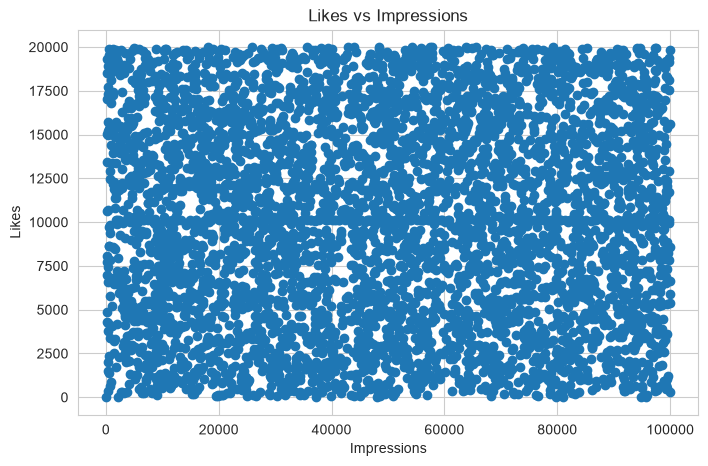

In [92]:
# Scatter plot – Likes vs Impressions
plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean['impression_count'],
    df_clean['likes']
)
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')
plt.show()

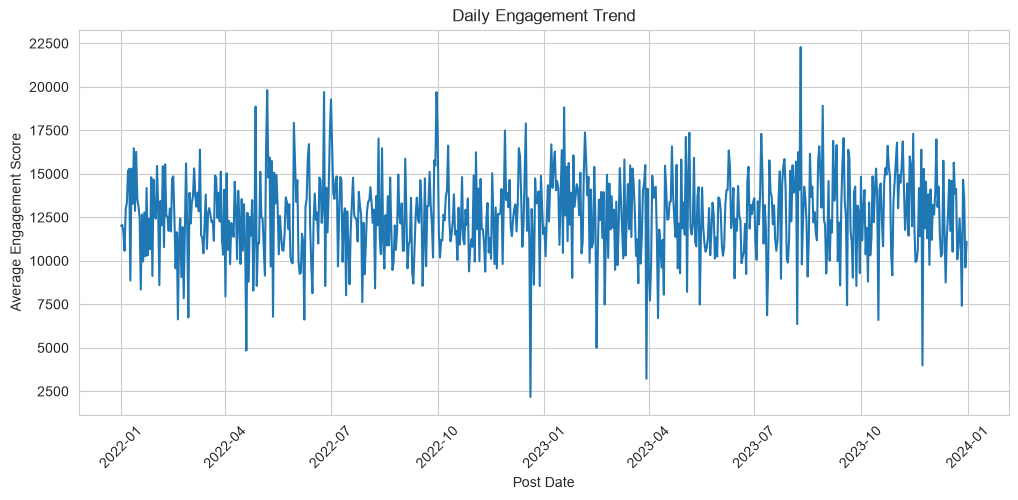

In [91]:
# Line plot – Daily engagement trend
daily_engagement = df_clean.groupby('post_date')[
    'engagement_score'
].mean()
plt.figure(figsize=(12, 5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.xlabel('Post Date')
plt.ylabel('Average Engagement Score')
plt.title('Daily Engagement Trend')
plt.xticks(rotation=45)
plt.show()

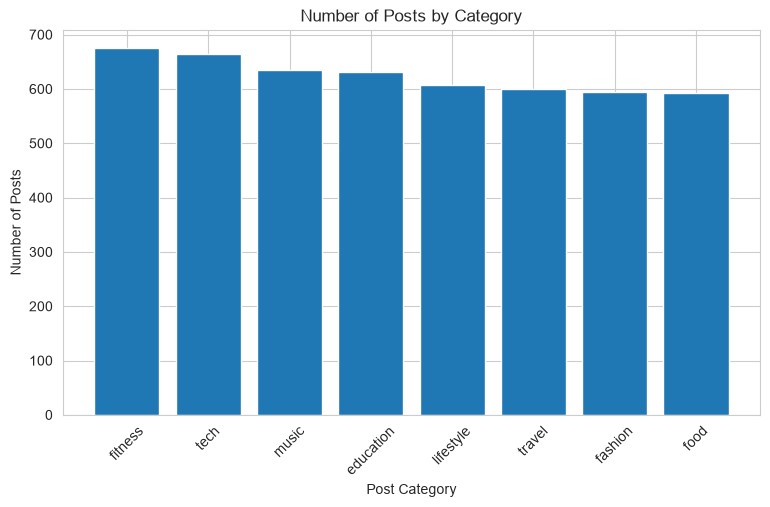

In [90]:
# Bar chart – Number of posts by category
posts_by_category = df_clean['post_category'].value_counts()
plt.figure(figsize=(9, 5))
plt.bar(posts_by_category.index, posts_by_category.values)
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Category')
plt.xticks(rotation=45)
plt.show()

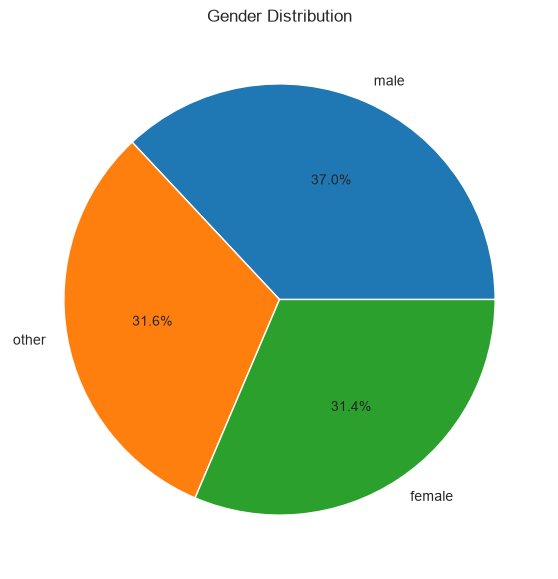

In [89]:
# Pie chart – Gender distribution
gender_counts = df_clean['gender'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%'
)
plt.title('Gender Distribution')
plt.show()

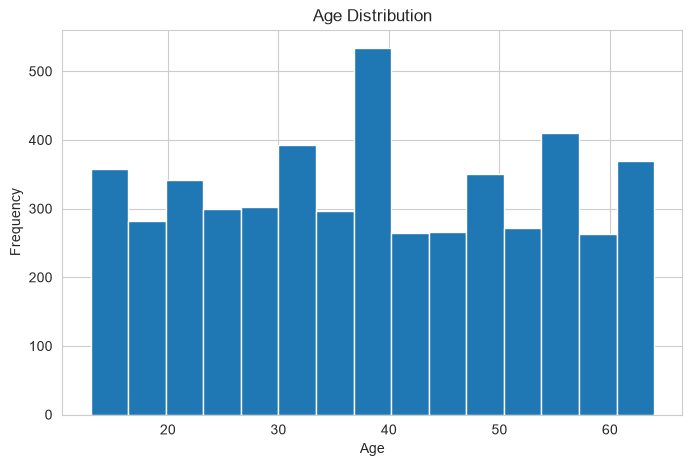

In [93]:
# Histogram – Age distribution
plt.figure(figsize=(8, 5))
plt.hist(df_clean['age'], bins=15)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

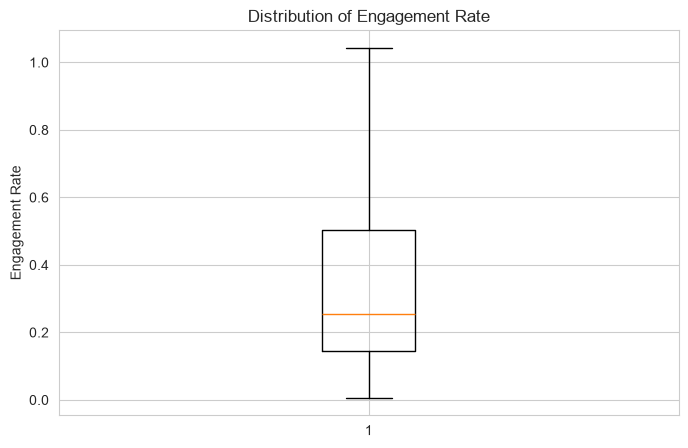

In [94]:
# Boxplot – Engagement rate
plt.figure(figsize=(8, 5))
plt.boxplot(df_clean['engagement_rate'])
plt.ylabel('Engagement Rate')
plt.title('Distribution of Engagement Rate')
plt.show()

#### Data visualization using Seaborn

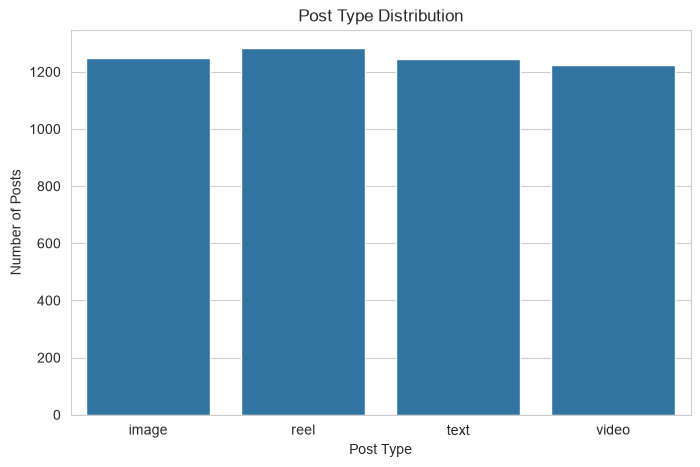

In [95]:
# Count plot – Post type distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='post_type')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Post Type Distribution')
plt.show()

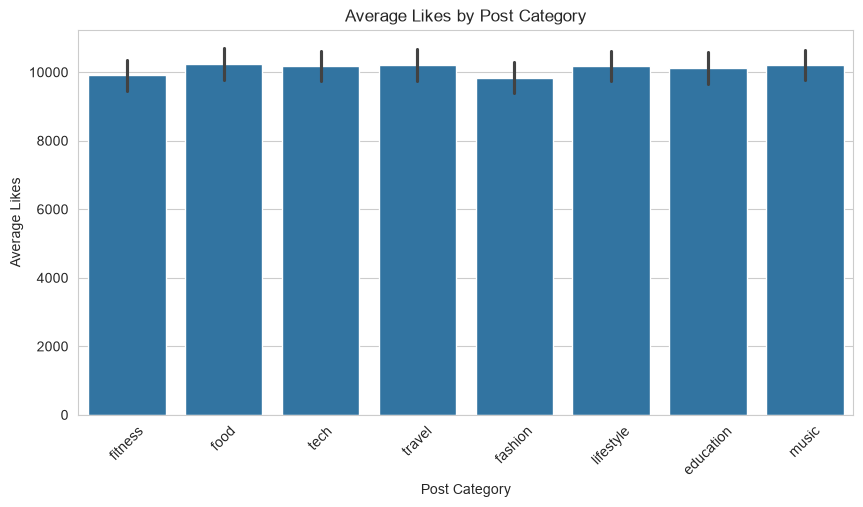

In [96]:
# Bar plot – Average likes by post category
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_clean,
    x='post_category',
    y='likes'
)

plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.title('Average Likes by Post Category')
plt.xticks(rotation=45)
plt.show()

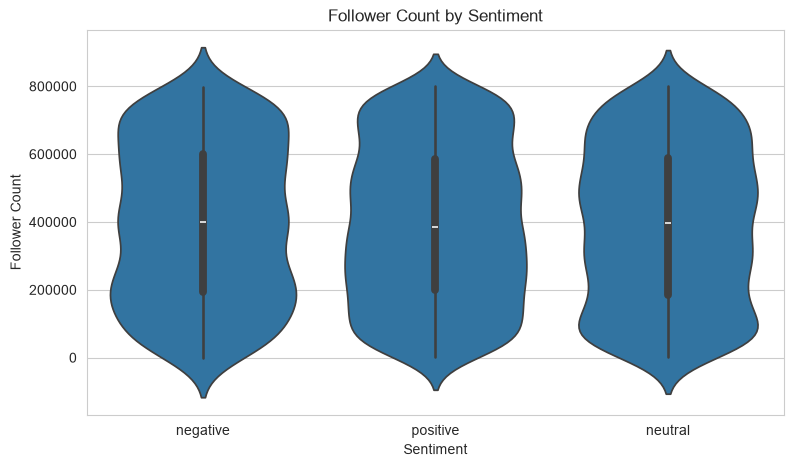

In [97]:
# Violin plot – Followers by sentiment
plt.figure(figsize=(9, 5))
sns.violinplot(
    data=df_clean,
    x='sentiment',
    y='follower_count'
)

plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.title('Follower Count by Sentiment')
plt.show()

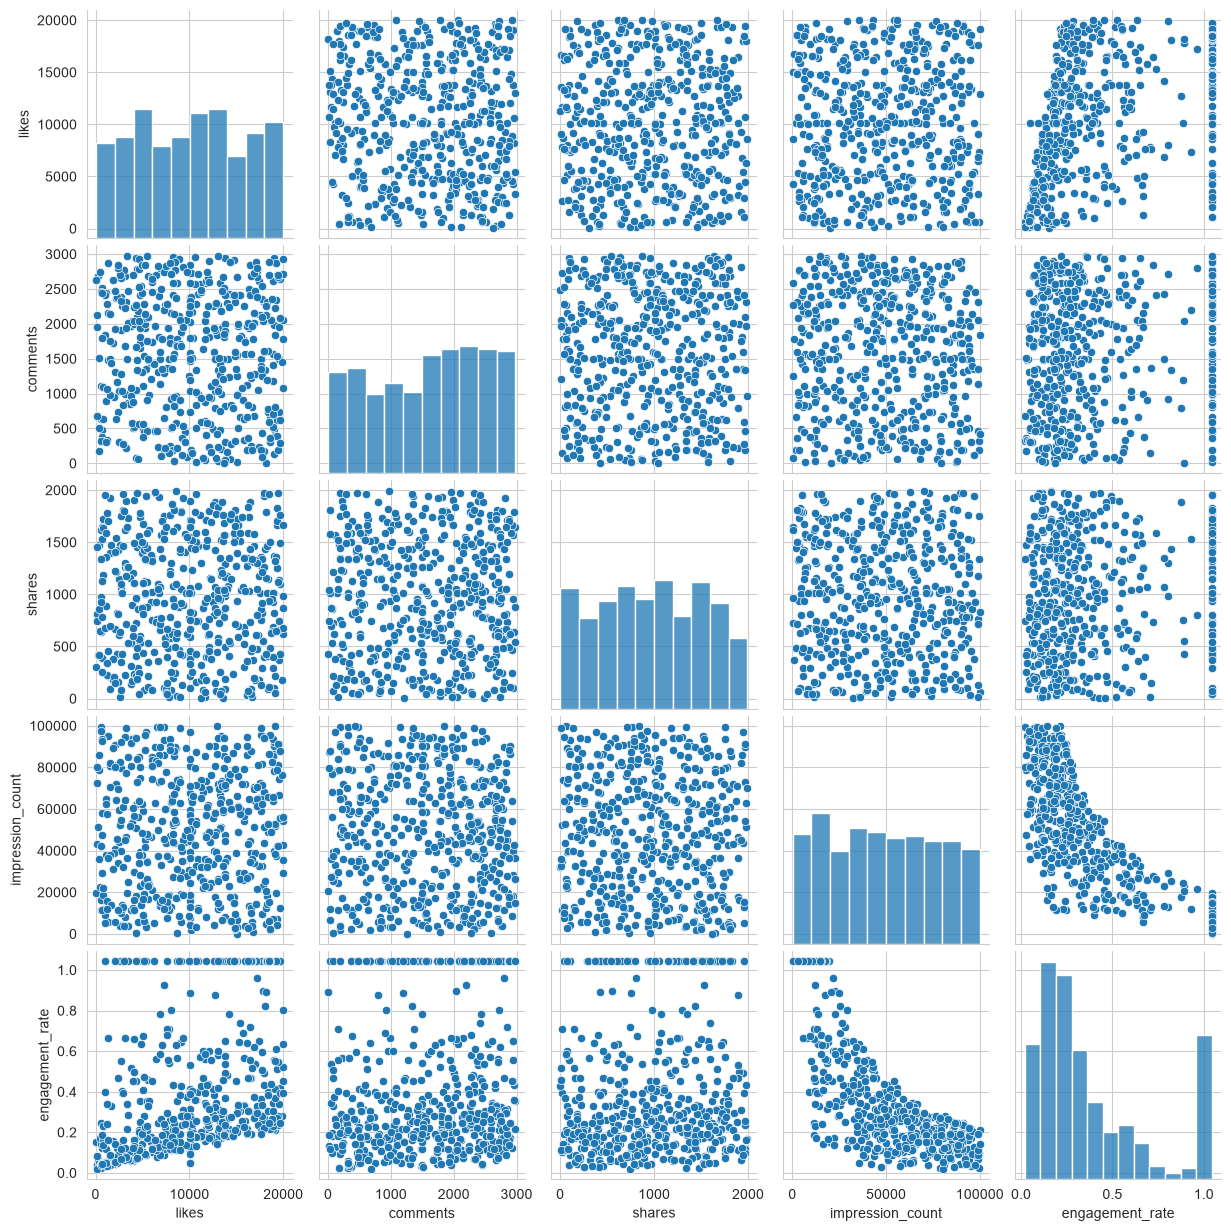

In [98]:
# Pair plot – Numerical features
pair_columns = [
    'likes',
    'comments',
    'shares',
    'impression_count',
    'engagement_rate'
]
sns.pairplot(
    df_clean[pair_columns].sample(
        min(500, len(df_clean)),
        random_state=42
    )
)

plt.show()

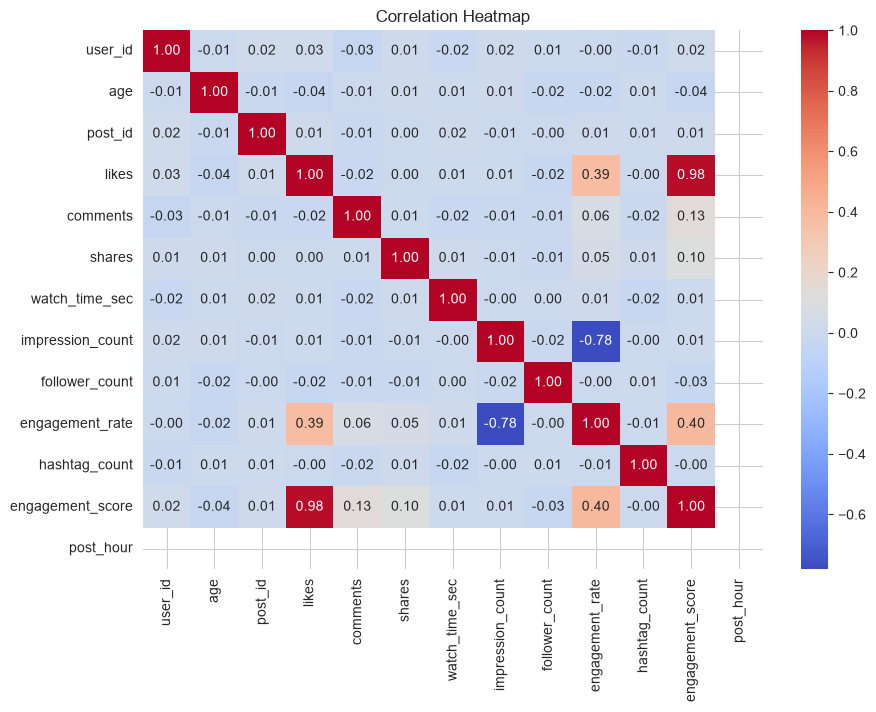

In [99]:
# Heatmap – Correlation between numerical variables
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

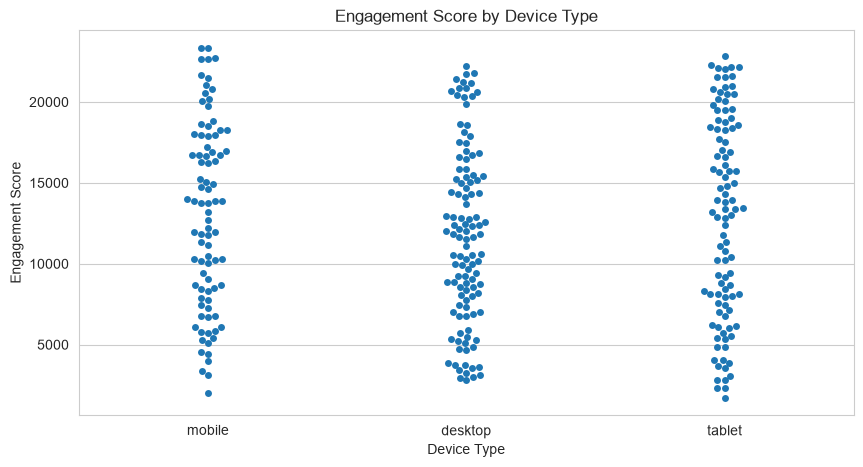

In [100]:
# Swarm plot – Engagement score by device type
plt.figure(figsize=(10, 5))
sns.swarmplot(
    data=df_clean.sample(
        min(300, len(df_clean)),
        random_state=42
    ),
    x='device_type',
    y='engagement_score'
)

plt.xlabel('Device Type')
plt.ylabel('Engagement Score')
plt.title('Engagement Score by Device Type')
plt.show()

#### Interactive visualizations using Plotly

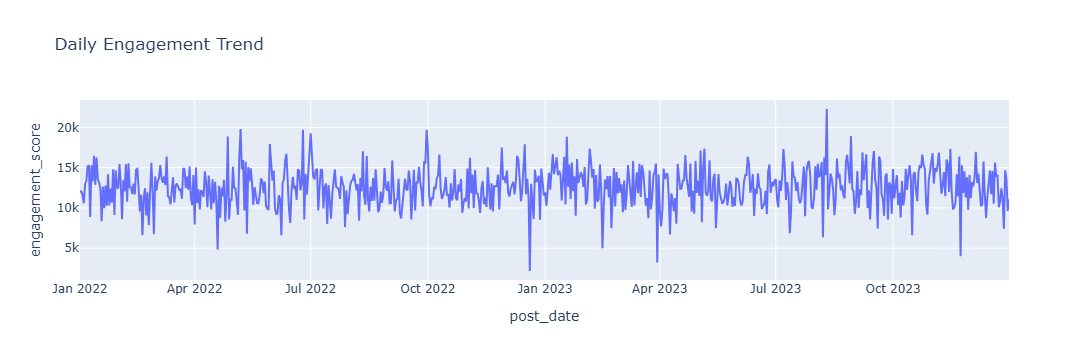

In [102]:
# Interactive line chart – Daily engagement trend
daily_plot = df_clean.groupby('post_date', as_index=False)[
    'engagement_score'
].mean()
fig = px.line(
    daily_plot,
    x='post_date',
    y='engagement_score',
    title='Daily Engagement Trend'
)
fig.show()

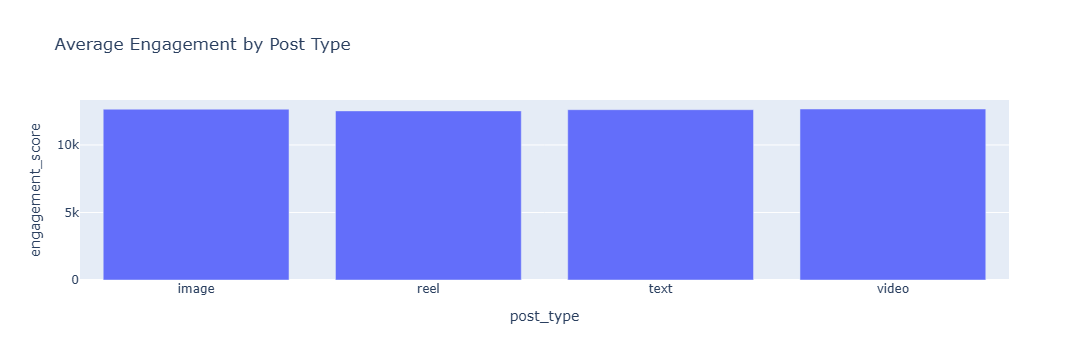

In [103]:
# Interactive bar chart – Average engagement by post type
post_type_summary = df_clean.groupby(
    'post_type',
    as_index=False
)['engagement_score'].mean()
fig = px.bar(
    post_type_summary,
    x='post_type',
    y='engagement_score',
    title='Average Engagement by Post Type'
)
fig.show()

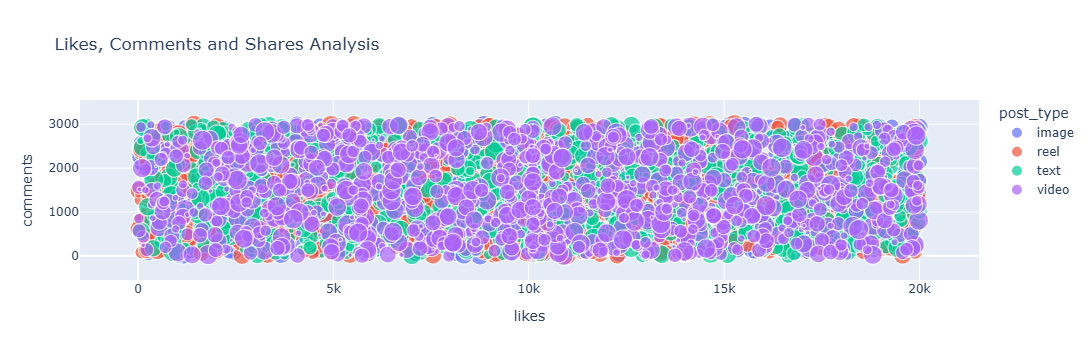

In [104]:
# Interactive scatter plot – Likes and comments
fig = px.scatter(
    df_clean,
    x='likes',
    y='comments',
    color='post_type',
    size='shares',
    hover_data=['post_category', 'country'],
    title='Likes, Comments and Shares Analysis'
)
fig.show()

### Final insights and findings

#### Identify the post type with the highest average engagement

In [105]:
post_type_engagement = df_clean.groupby(
    'post_type'
)['engagement_score'].mean().sort_values(ascending=False)

post_type_engagement

post_type
video    12664.594286
image    12649.390537
text     12613.243775
reel     12524.031567
Name: engagement_score, dtype: float64

#### Identify the best-performing post category

In [106]:
category_ranking

,post_category,total_posts,average_likes,average_comments,average_shares,average_engagement
5,music,635,10205.749606,1558.710236,1024.089764,12788.549606
3,food,593,10225.522766,1510.876897,1002.801012,12739.200675
6,tech,665,10171.571429,1505.548872,1009.369925,12686.490226
7,travel,600,10196.304167,1485.948333,968.306667,12650.559167
4,lifestyle,607,10180.559308,1467.840198,991.140033,12639.539539
0,education,631,10126.487322,1455.337559,996.445325,12578.270206
2,fitness,675,9914.602222,1501.142222,1042.047407,12457.791852
1,fashion,594,9843.356902,1530.540404,982.523569,12356.420875


#### Compare average engagement rate by country

In [109]:
country_engagement = df_clean.groupby(
    'country'
)['engagement_rate'].mean().sort_values(ascending=False)

country_engagement

country
australia    0.401197
japan        0.390418
uae          0.388628
germany      0.384047
canada       0.382452
brazil       0.381073
france       0.373147
usa          0.363791
uk           0.359632
india        0.343157
Name: engagement_rate, dtype: float64

#### Analyse engagement across different age groups

In [110]:
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 20, 30, 40, 50, 65, 100],
    labels=['Below 20', '20-30', '30-40', '40-50', '50-65', 'Above 65']
)
age_comparison = df_clean.groupby(
    'age_group',
    observed=False
)['engagement_score'].mean()
age_comparison

age_group
Below 20    12854.529820
20-30       12622.617737
30-40       12938.497736
40-50       12658.455732
50-65       12164.991622
Above 65             NaN
Name: engagement_score, dtype: float64

In [111]:
# Compare verified and non-verified accounts
verified_comparison = df_clean.groupby(
    'is_verified'
)[['likes', 'comments', 'shares', 'engagement_score']].mean()
verified_comparison

,likes,comments,shares,engagement_score
is_verified,,,,
False,10137.201129,1505.511401,1001.599292,12644.311822
True,9824.533126,1469.573499,1015.173913,12309.280538


#### Identify the best posting hour based on impressions

In [112]:
hour_comparison = df_clean.groupby(
    'post_hour'
)['impression_count'].mean().sort_values(ascending=False)

hour_comparison

post_hour
0    50013.7328
Name: impression_count, dtype: float64

#### Analyse watch time by device type

In [113]:
device_comparison = df_clean.groupby(
    'device_type'
)['watch_time_sec'].mean().sort_values(ascending=False)

device_comparison

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

#### Identify the sentiment with the highest average engagement

In [115]:
sentiment_comparison = df_clean.groupby(
    'sentiment'
)[['engagement_score', 'engagement_rate']].mean().sort_values(
    by='engagement_score',
    ascending=False
)
sentiment_comparison

,engagement_score,engagement_rate
sentiment,,
negative,12731.498958,0.380845
positive,12665.799443,0.372769
neutral,12448.163720,0.379722


#### Compare likes, comments and shares across sentiment groups

In [116]:
sentiment_behaviour = df_clean.groupby(
    'sentiment'
)[['likes', 'comments', 'shares', 'watch_time_sec']].mean()
sentiment_behaviour

,likes,comments,shares,watch_time_sec
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,4054.639583
neutral,9923.194499,1528.404060,996.565160,4031.823183
positive,10180.062077,1480.650617,1005.086749,3988.646240


#### Interpretation 
Video posts recorded the highest average engagement score, indicating that users interacted more with video content compared to other post types. Among the content categories, Music achieved the highest average engagement score, while Fashion recorded the lowest. Country-wise analysis showed that Australia had the highest average engagement rate, whereas India had the lowest. Users aged 30–40 recorded the highest average engagement score, indicating greater interaction within this age group. Non-verified accounts showed a slightly higher average engagement score than verified accounts, suggesting that verification status alone does not guarantee higher engagement. Mobile users recorded the highest average watch time compared to tablet and desktop users, highlighting the importance of mobile devices in social media content consumption. Sentiment analysis revealed that negative sentiment posts achieved the highest average engagement score, while neutral sentiment posts recorded the lowest. Correlation analysis showed a strong positive relationship between likes and engagement score (0.984), while impressions and engagement rate showed a strong negative relationship (-0.781), indicating an inverse association between these two metrics.

### Conclusion
The analysis highlights variations in social media engagement based on post type, content category, country, age group, account verification status, device type and sentiment. Video posts and music-related content performed better in terms of average engagement score. Australia recorded the highest average engagement rate, while mobile users showed the highest watch time.

The findings demonstrate how Python-based data analysis and visualization can help identify engagement patterns, understand audience behaviour and support data-driven social media content strategies.